# Tarea 2 · Fritz renegocia, parte 2: el enjambre

**Curso:** Optimización metaheurística orientada a modelación hidrogeológica · UNAM, Instituto de Geología · noviembre de 2026
**Entrega:** antes del martes 17 de noviembre · **Tiempo estimado:** unas 2 horas (es el trabajo asíncrono de la sesión) · **Valor:** se ofrecen 12 puntos (10 automáticos, 2 de interpretación); la calificación máxima es 10

**Para aprobar:** este cuaderno se aprueba con **6 de 10** puntos. Con **2 de los 4 cuadernos** aprobados, el examen del curso está aprobado.

**Tú eliges qué contestar.** El cuaderno ofrece 12 puntos, pero la calificación se cierra en 10: puedes dejar sin contestar hasta 2 puntos de las etapas que
quieras y aun así llegar a 10, o contestarlo todo para asegurar. Las etapas 1 y 2 son sobre el **algoritmo** (cómo se mueve una partícula y qué hace cada
término); de la 3 en adelante, sobre cómo **usarlo** en el problema de Fritz.

---

## El problema

En la Tarea 1 resolviste con `linprog` el problema de Fritz con tus propios datos. Aquí todos usamos los del cuaderno: el máximo bombeo con los pozos a
3 m como máximo, el humedal a **1.25 m** y el pozo 3 en **300 m³/d**. Fritz ahora pregunta dos cosas: **¿el enjambre llega a lo mismo sin usar la matriz?** y **¿qué pasa si además pago la luz?** Es la ruta del
cuaderno de la sesión 2, con los mismos datos para todos:

$$
\max Z = \sum_{i=1}^{3} p_i \quad \text{(etapas 4 a 6)}, \qquad
\max B = P \sum_{i=1}^{3} p_i - \sum_{i=1}^{3} c_i\,p_i\,\big(\text{H}_i - h_i^0 + s_i(\mathbf{p})\big) \quad \text{(etapas 7 a 9)}
$$

con $P = 0.11$ \$/m³, $c = 0.01, 0.015, 0.02$; $\text{H} = 40$ m y $h^0 = 34, 34, 15$ m.

| Etapa | Pregunta de Fritz | Puntos |
|---|---|---|
| 1 | «Enséñame cómo se mueve una partícula» (un paso de la ecuación, a mano) | 1 |
| 2 | «¿Qué pasa si apago un término? ¿Y cuándo paro?» (inercia, memoria, grupo y el criterio de paro) | 1 |
| 3 | «Primero aprende a usar la herramienta» (tu propia función y el presupuesto) | 1 |
| 4 | «¿Cuánto debo castigar a quien rompa las reglas?» (la escala del castigo) | 1 |
| 5 | «¿Qué tan cerca queda el enjambre de la respuesta exacta?» | 1 |
| 6 | «¿Y si lo corro otra vez?» (diez semillas) | 1 |
| 7 | «Si pago la luz, ¿cuánto me conviene bombear?» (el beneficio neto) | 1.5 |
| 8 | «¿Y si sube el precio del agua?» (cuándo mandan las reglas) | 1 |
| 9 | «¿Y si el acuífero no es como creemos?» (la geología 7) | 1.5 |
| 10 | «Explícamelo en palabras.» | 2 |

Igual que en la Tarea 1: escribe valores en los recuadros **INGRESA AQUÍ LOS DATOS SOLICITADOS**, ejecuta, y revisa con `grader.check`.
Todo lo que se pide está hecho en el cuaderno de la sesión 2 (`S2_enjambre_pso_rrwpt.ipynb`) con los datos de la clase. **No es una prueba de Python:**
cada recuadro dice qué forma tiene la respuesta (un número, `True` o `False`, un nombre entre comillas) y trae un ejemplo; cuando hay que completar una
fórmula, el enunciado la da en palabras y las piezas difíciles ya están escritas.

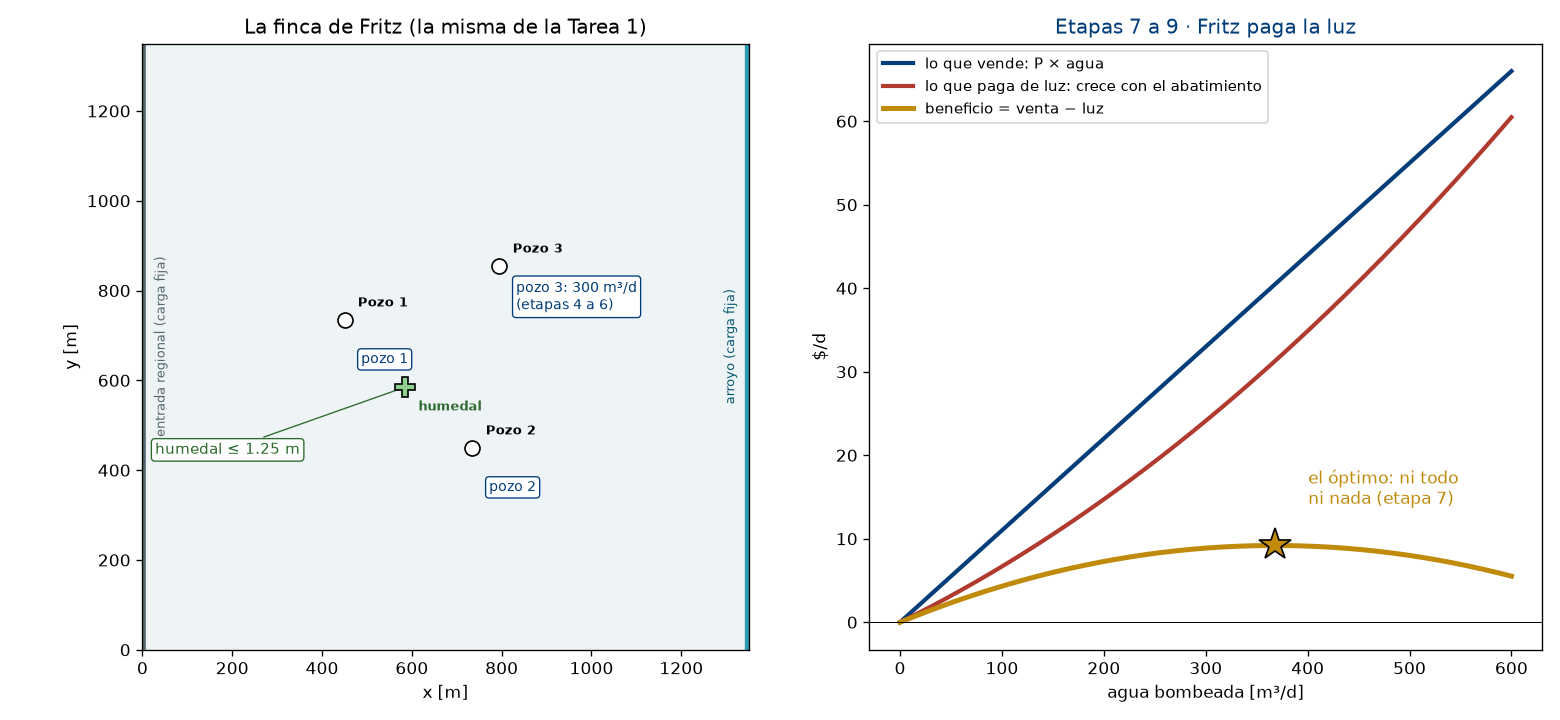

*Izquierda: la finca de la Tarea 1. Derecha: en cuanto Fritz paga la luz, bombear todo deja de convenir; el óptimo queda en medio.*

In [ ]:
# Preparación (se ejecuta sola). Si tarda más de un minuto, mira el último paso impreso y díselo al instructor.
import sys, os, glob
print("paso 1 de 5: localizando este cuaderno…", flush=True)
_ruta = os.path.abspath(globals().get("__vsc_ipynb_file__") or next(iter(sorted(glob.glob("Tarea_2*.ipynb"))), "Tarea_2.ipynb"))
print("          ", _ruta, flush=True)
for _modulo in ("hidra", "pso"):           # hidra.py vive en Curso_Opt y pso.py en Session_2/Información/codigo: los buscamos subiendo de carpeta
    try:
        __import__(_modulo)
    except ImportError:
        for _inicio in (os.path.dirname(_ruta), os.getcwd()):
            _d = _inicio
            for _ in range(6):
                _c = next((c for c in (_d, os.path.join(_d, "Información", "codigo")) if os.path.exists(os.path.join(c, _modulo + ".py"))), None)
                if _c:
                    sys.path.insert(0, _c); break
                _d = os.path.dirname(_d)
print("paso 2 de 5: cargando numpy, scipy y matplotlib…", flush=True)
import numpy as np
from scipy.optimize import linprog
import matplotlib.pyplot as plt
print("paso 3 de 5: cargando hidra y pso…", flush=True)
import hidra, pso
alpha = hidra.matriz_respuesta(); alpha_h = hidra.coeficientes_humedal()
print("paso 4 de 5: cargando otter (las comprobaciones)…", flush=True)
import otter
print("paso 5 de 5: preparando el calificador…", flush=True)
grader = otter.Notebook(_ruta)

S_MAX, S_HUM, P3 = 3.0, 1.25, 300.0                    # las reglas y el contrato del pozo 3 (los del cuaderno de la sesión)
PRECIO = 0.11                                          # $ por m³
C_QP = np.array([0.01, 0.015, 0.02]); GSLEV = np.array([40.0, 40.0, 40.0]); H0 = np.array([34.0, 34.0, 15.0])

def legal(p, al=None, ah=None, tol=0.01):
    # True si la decisión p respeta las reglas (con una tolerancia de 1 cm)
    al = alpha if al is None else al; ah = alpha_h if ah is None else ah
    return bool((al @ p <= S_MAX + tol).all() and ah @ p <= S_HUM + tol)
print("Herramientas listas.")

## Etapa 0 · Tus datos (sin puntos)

Escribe el **mismo correo** de la Tarea 1: identifica tu entrega. Esta tarea usa los mismos datos para todos, los del cuaderno de la sesión.

In [ ]:
# ╔════════════════════════════════════════════════════════════╗
# ║   INGRESA AQUÍ LOS DATOS SOLICITADOS (sustituye los ...)   ║
# ╚════════════════════════════════════════════════════════════╝
# Tu correo de inscripción, entre comillas. El mismo de la Tarea 1.
IDENTIFICADOR = ...

# ──────────────────────────────────────────────────────────────
#   NO MODIFIQUES DE AQUÍ EN ADELANTE: esta parte se ejecuta sola
# ──────────────────────────────────────────────────────────────
print("Entrega de:", IDENTIFICADOR)
print("Datos (iguales para todos): pozos ≤", S_MAX, "m, humedal ≤", S_HUM, "m, pozo 3 en", P3, "m³/d, precio", PRECIO, "$/m³.")

In [ ]:
grader.check("q0")

## Etapa 1 · Cómo se mueve una partícula (1 punto)

**Problema.** Antes de usar el enjambre, Fritz quiere ver que entiendes qué hace **una** partícula en **una** iteración (sección 1.5 del cuaderno y la
lámina de la ecuación). En la notación de `pso.py`:

$$
\mathbf{v} \leftarrow \underbrace{w\,\mathbf{v}}_{\text{inercia}} + \underbrace{c_1\, r_1\,(\mathbf{p} - \mathbf{x})}_{\text{memoria}} + \underbrace{c_2\, r_2\,(\mathbf{g} - \mathbf{x})}_{\text{grupo}}, \qquad \mathbf{x} \leftarrow \mathbf{x} + \mathbf{v}
$$

donde $\mathbf{x}$ es la posición de la partícula, $\mathbf{v}$ su velocidad, $\mathbf{p}$ lo mejor que **ella** ha visto y $\mathbf{g}$ lo mejor que ha visto
**el enjambre**. Para este paso: $\mathbf{x} = (1, 4)$, $\mathbf{v} = (0.5, -1)$, $\mathbf{p} = (2, 3)$, $\mathbf{g} = (3, -1)$, $w = 0.7$, $c_1 = 1.5$,
$c_2 = 2$, y los dos números al azar ya «tirados»: $r_1 = 0.5$ y $r_2 = 0.25$.

**Pregunta.**

1. Completa los términos de **memoria** y **grupo**, la nueva velocidad y la nueva posición. El de inercia ya está escrito y los otros dos tienen la misma
   forma: un número que multiplica al vector entre paréntesis. Puedes hacer la cuenta a mano y escribir los dos números, o escribir la operación.
2. La celda imprime el tamaño de cada término y lo dibuja. Escribe `termino_dominante`: el término más largo, el que más jala en este paso.

In [ ]:
# ╔════════════════════════════════════════════════════════════╗
# ║   INGRESA AQUÍ LOS DATOS SOLICITADOS (sustituye los ...)   ║
# ╚════════════════════════════════════════════════════════════╝
# La partícula en este paso (ya escrito): posición x, velocidad v, su mejor p y el mejor del enjambre g; los parámetros y los dos números al azar
x = np.array([1.0, 4.0]); v = np.array([0.5, -1.0]); p = np.array([2.0, 3.0]); g = np.array([3.0, -1.0])
w, c1, c2, r1, r2 = 0.7, 1.5, 2.0, 0.5, 0.25
# Los tres términos (cada uno es un vector de dos números). El de inercia ya está escrito: w por v
inercia = w * v
# memoria = c1 por r1 por (p menos x);  grupo = c2 por r2 por (g menos x). Ejemplo de la forma: 0.7 * v  o bien  np.array([0.35, -0.7])
memoria = ...
grupo = ...
# La nueva velocidad es la suma de los tres términos; la nueva posición es la posición más la nueva velocidad
v_nueva = ...
x_nueva = ...

# ──────────────────────────────────────────────────────────────
#   NO MODIFIQUES DE AQUÍ EN ADELANTE: esta parte se ejecuta sola
# ──────────────────────────────────────────────────────────────
terminos = {"inercia": inercia, "memoria": memoria, "grupo": grupo}
print("término     vector            tamaño")
for nombre, t in terminos.items():
    print(f"{nombre:10s}  {str(np.round(t, 3)):16s}  {np.linalg.norm(t):.2f}")
print("velocidad nueva:", np.round(v_nueva, 3), "  posición nueva:", np.round(x_nueva, 3))
fig, ax = plt.subplots(figsize=(8, 6))
colores = {"inercia": "#54696F", "memoria": "#2E9BB5", "grupo": "#C08A0B"}
origen = x.copy()
for nombre, t in terminos.items():
    ax.annotate("", xy=origen + t, xytext=origen, arrowprops=dict(arrowstyle="->", lw=3, color=colores[nombre]))
    ax.annotate(nombre, origen + t / 2, xytext={"inercia": (12, 4), "memoria": (14, -14), "grupo": (12, 0)}[nombre], textcoords="offset points",
                color=colores[nombre], fontsize=11, fontweight="bold")
    origen = origen + t
ax.plot(*x, "o", ms=11, color="#1B2B33", label="x (ahora)"); ax.plot(*p, "s", ms=10, color="#2E9BB5", label="p (su mejor)")
ax.plot(*g, "*", ms=17, color="#C08A0B", label="g (mejor del enjambre)")
ax.plot(*x_nueva, "o", ms=11, mfc="none", mec="#B03A2E", mew=2.5, label="x nueva = x + v nueva")
ax.annotate("", xy=x_nueva, xytext=x, arrowprops=dict(arrowstyle="->", lw=1.5, ls="--", color="#B03A2E"))
ax.set_xlim(-0.5, 5.5); ax.set_ylim(-1.8, 4.8); ax.set_aspect("equal"); ax.grid(alpha=0.3)
ax.set_xlabel("x₁"); ax.set_ylabel("x₂"); ax.legend(loc="lower left", fontsize=9.5)
ax.set_title("Un paso de la partícula: los tres términos, uno tras otro"); plt.tight_layout(); plt.show()

In [ ]:
# ╔════════════════════════════════════════════════════════════╗
# ║   INGRESA AQUÍ LOS DATOS SOLICITADOS (sustituye los ...)   ║
# ╚════════════════════════════════════════════════════════════╝
# El término más largo de la tabla de arriba: escribe "inercia", "memoria" o "grupo" (entre comillas)
termino_dominante = ...

# ──────────────────────────────────────────────────────────────
#   NO MODIFIQUES DE AQUÍ EN ADELANTE: esta parte se ejecuta sola
# ──────────────────────────────────────────────────────────────
print("En este paso manda el término de", termino_dominante + ": la partícula se va hacia", "g" if termino_dominante == "grupo" else "p" if termino_dominante == "memoria" else "donde ya iba")

In [ ]:
grader.check("q1")

## Etapa 2 · Apaga un término y decide cuándo parar (1 punto)

**Problema.** La celda corre el mismo enjambre (20 partículas, 100 iteraciones, semilla 0) sobre Sphere, $f(\mathbf{x}) = x_1^2 + x_2^2$, tres veces:
**completo** ($c_1 = 1.5$, $c_2 = 2$), **sin grupo** ($c_2 = 0$) y **sin memoria** ($c_1 = 0$), como en el «tu turno» de la sección 1.5 del cuaderno.
Imprime el mejor costo final de cada corrida y, para la completa, el mejor costo cada 10 iteraciones (sección 1.6: ¿cuándo parar?).

**Pregunta.** Lee la salida y escribe:

1. `sin_grupo_llega` y `sin_memoria_llega`: `True` si esa corrida llegó al fondo (mejor costo final menor que 0.001), `False` si no.
2. `termino_indispensable`: el término sin el cual el enjambre **no** llega.
3. `iteracion_suficiente`: la **primera** iteración de la tabla en la que el mejor costo de la corrida completa ya está por debajo de $10^{-6}$; es
   decir, donde un criterio de paro por tolerancia la habría detenido.

In [ ]:
def Sphere(x):
    return sum(x**2)

problema_sphere = {'CostFunction': Sphere, 'nVar': 2, 'VarMin': -5, 'VarMax': 5}
corridas = {}
print("corrida                 c1    c2   mejor costo final   posición final")
for nombre, c1_, c2_ in [("completo", 1.5, 2), ("sin grupo (c2 = 0)", 1.5, 0), ("sin memoria (c1 = 0)", 0, 2)]:
    np.random.seed(0)
    g_, _ = pso.PSO(problema_sphere, MaxIter=100, PopSize=20, c1=c1_, c2=c2_, w=0.9, wdamp=0.99, verbose=False)
    corridas[nombre] = (g_['cost'], list(pso.historial))
    print(f"{nombre:22s} {c1_:4.1f}  {c2_:4.1f}   {g_['cost']:.1e}           {np.round(g_['position'], 3)}")
historial_completo = corridas["completo"][1]
tabla_paro = {it: historial_completo[it - 1] for it in range(10, 101, 10)}
print()
print("corrida completa: mejor costo cada 10 iteraciones")
for it, c in tabla_paro.items():
    print(f"   iteración {it:3d}:  {c:.1e}")
fig, ax = plt.subplots(figsize=(8, 4.3))
for nombre, (c, h) in corridas.items():
    ax.semilogy(np.arange(1, len(h) + 1), np.maximum(h, 1e-20), lw=2, label=nombre)
ax.axhline(1e-6, color='k', ls=':', label='tolerancia 1e-6'); ax.set_xlabel('iteración'); ax.set_ylabel('mejor costo (escala log)'); ax.legend()
ax.set_title('El mismo enjambre con un término apagado'); plt.tight_layout(); plt.show()

In [ ]:
# ╔════════════════════════════════════════════════════════════╗
# ║   INGRESA AQUÍ LOS DATOS SOLICITADOS (sustituye los ...)   ║
# ╚════════════════════════════════════════════════════════════╝
# ¿Llegó al fondo (mejor costo final menor que 0.001)? Escribe True o False para cada corrida, leyendo la tabla de arriba
sin_grupo_llega = ...
sin_memoria_llega = ...
# El término sin el cual el enjambre no llega: "inercia", "memoria" o "grupo" (entre comillas)
termino_indispensable = ...
# La primera iteración de la tabla (10, 20, …, 100) con el mejor costo de la corrida completa por debajo de 1e-6 (un número de la tabla)
iteracion_suficiente = ...

# ──────────────────────────────────────────────────────────────
#   NO MODIFIQUES DE AQUÍ EN ADELANTE: esta parte se ejecuta sola
# ──────────────────────────────────────────────────────────────
print("sin grupo:", "llega" if sin_grupo_llega else "no llega", "| sin memoria:", "llega" if sin_memoria_llega else "no llega",
      "| el término indispensable es", termino_indispensable)
print("Con la tolerancia 1e-6 bastaban", iteracion_suficiente, "iteraciones de 100: lo demás fue gasto.")

In [ ]:
grader.check("q2")

## Etapa 3 · Primero, la herramienta: tu propia función (1 punto)

**Problema.** Antes de tocar el acuífero, Fritz quiere saber si sabes **usar** PSO (sección 1.6 del cuaderno, ejemplo 2, y el ejemplo 6 del apéndice «En casa»). La receta: una función que
recibe el vector de decisión y devuelve **un número**, el diccionario `problem`, los parámetros y `pso.PSO`. Lo practicamos con un valle de mínimo conocido:

$$
f(x_1, x_2) = (x_1 - 3)^2 + (x_2 + 1)^2, \qquad \text{mínimo } f = 0 \text{ en } (3, -1)
$$

**Pregunta.**

1. Completa la función `mi_funcion`: recibe `x` (un arreglo de dos números) y devuelve el valor de $f$, escrito con `x[0]` y `x[1]`, como `Sphere` en la
   sección 1.1 del cuaderno.
2. Ejecuta: la celda corre PSO con cuatro presupuestos (partículas × iteraciones) y dibuja la convergencia. Escribe `evaluaciones_suficientes`: el **menor**
   número de evaluaciones de la tabla con mejor costo menor que 0.001.

In [ ]:
# ╔════════════════════════════════════════════════════════════╗
# ║   INGRESA AQUÍ LOS DATOS SOLICITADOS (sustituye los ...)   ║
# ╚════════════════════════════════════════════════════════════╝
# La función objetivo del valle: recibe x (x[0] es x₁ y x[1] es x₂) y devuelve f = (x₁ − 3)² + (x₂ + 1)².
# Sustituye los ... por la fórmula. En Python el cuadrado se escribe **2: por ejemplo, (x[0] - 3)**2 es (x₁ − 3)²
def mi_funcion(x):
    f = ...
    return f

# ──────────────────────────────────────────────────────────────
#   NO MODIFIQUES DE AQUÍ EN ADELANTE: esta parte se ejecuta sola
# ──────────────────────────────────────────────────────────────
problema_valle = {'CostFunction': mi_funcion, 'nVar': 2, 'VarMin': -5, 'VarMax': 5}
tabla_presupuesto = {}; curvas = {}
print("partículas  iteraciones  evaluaciones   mejor costo   posición")
for pop_size, max_iter in [(5, 10), (10, 20), (20, 50), (50, 100)]:
    np.random.seed(0)
    g, _ = pso.PSO(problema_valle, MaxIter=max_iter, PopSize=pop_size, c1=1.5, c2=2, w=1, wdamp=0.995, verbose=False)
    tabla_presupuesto[pop_size * max_iter] = g['cost']; curvas[(pop_size, max_iter)] = list(pso.historial)
    print(f"{pop_size:10d} {max_iter:12d} {pop_size * max_iter:13d}   {g['cost']:.2e}   {np.round(g['position'], 3)}")
fig, ax = plt.subplots(figsize=(8, 4.3))
for (ps, mi), h in curvas.items():
    ax.semilogy(np.arange(len(h)) * ps, np.maximum(h, 1e-16), lw=2, label=f"{ps} × {mi}")
ax.axhline(1e-3, color='k', ls=':', label='meta: 0.001')
ax.set_xlabel('evaluaciones gastadas'); ax.set_ylabel('mejor costo (escala log)'); ax.legend(title='partículas × iteraciones')
ax.set_title('Tu función: el mismo enjambre con cuatro presupuestos'); plt.tight_layout(); plt.show()

In [ ]:
# ╔════════════════════════════════════════════════════════════╗
# ║   INGRESA AQUÍ LOS DATOS SOLICITADOS (sustituye los ...)   ║
# ╚════════════════════════════════════════════════════════════╝
# Un número de la columna «evaluaciones» de la tabla de arriba: el menor con mejor costo menor que 0.001. Ejemplo: 50
evaluaciones_suficientes = ...

# ──────────────────────────────────────────────────────────────
#   NO MODIFIQUES DE AQUÍ EN ADELANTE: esta parte se ejecuta sola
# ──────────────────────────────────────────────────────────────
print("Con", evaluaciones_suficientes, "evaluaciones el enjambre ya está en el fondo del valle.")

In [ ]:
grader.check("q3")

## Etapa 4 · ¿Cuánto castigar a quien rompe las reglas? (1 punto)

**Problema.** El enjambre no conoce las reglas: hay que meterlas en la calificación (sección 2.4 del cuaderno). Con el castigo **graduado**,

$$
\text{calificación}(\mathbf{p}) = \sum_i p_i - M \left[\, \sum_j \max(0,\ s_j - 3) + \max(0,\ s_h - 1.25) \,\right]
$$

donde el corchete es el **exceso**: cuántos metros se pasan las reglas. Si $M$ es pequeño, al enjambre le conviene romperlas.

**Pregunta.**

1. Completa la función `exceso`: recibe los abatimientos en los pozos `s` (un arreglo de 3) y en el humedal `s_h` (un número) y devuelve los metros de
   exceso, como en la sección 2.4 del cuaderno. Las dos piezas (cuánto se pasa cada pozo y cuánto se pasa el humedal) ya están escritas; tú decides cómo
   se juntan en un solo número.
2. Elige `M_CASTIGO` (entre 1 y 1 000 000) para que el enjambre (50 partículas × 200 iteraciones) termine **dentro de las reglas** y a menos de 1 % de la
   respuesta exacta. Empieza con `M_CASTIGO = 50`, mira dónde queda la cruz y sube hasta que quede sobre la estrella.

In [ ]:
# ╔════════════════════════════════════════════════════════════╗
# ║   INGRESA AQUÍ LOS DATOS SOLICITADOS (sustituye los ...)   ║
# ╚════════════════════════════════════════════════════════════╝
# El exceso de una decisión, en metros: cuánto se pasan las reglas. Las dos piezas ya están escritas; falta juntarlas
def exceso(s, s_h):
    exceso_pozos = np.maximum(s - S_MAX, 0)      # ya escrito: cuánto se pasa cada pozo (un arreglo de 3; vale 0 donde no se pasa)
    exceso_humedal = max(s_h - S_HUM, 0)         # ya escrito: cuánto se pasa el humedal (un número; 0 si no se pasa)
    # metros = la suma de los tres pozos más el humedal. Sintaxis: np.sum(exceso_pozos) suma los tres
    metros = ...
    return metros
# El peso del castigo, en m³/d por metro de exceso (un número entre 1 y 1 000 000). Empieza con 50 y sube
M_CASTIGO = ...

# ──────────────────────────────────────────────────────────────
#   NO MODIFIQUES DE AQUÍ EN ADELANTE: esta parte se ejecuta sola
# ──────────────────────────────────────────────────────────────
def Restriction(x):
    x[2] = P3                 # reparación: el pozo 3 siempre en 300 m³/d
    return x

def Pumping_graduado(x):
    return np.sum(x) - M_CASTIGO * exceso(alpha @ x, alpha_h @ x)

exacto = linprog([-1, -1], A_ub=np.vstack([alpha[:, :2], alpha_h[:2]]), b_ub=np.append(S_MAX - alpha[:, 2] * P3, S_HUM - alpha_h[2] * P3),
                 bounds=[(0, 1000)] * 2, method='highs')
Z_exacto = exacto.x.sum() + P3
problem = {'CostFunction': Pumping_graduado, 'nVar': 3, 'VarMin': 0, 'VarMax': 1000, 'ResFunction': Restriction, 'MinProblem': 0}
np.random.seed(0)
g2, _ = pso.PSO(problem, MaxIter=200, PopSize=50, c1=1.5, c2=2, w=1, wdamp=0.995, verbose=False)
p_castigo = g2['position']
print(f"M = {M_CASTIGO}: p = {np.round(p_castigo, 1)} m³/d, total {p_castigo.sum():.1f} (exacto {Z_exacto:.2f})")
print(f"abatimientos {np.round(alpha @ p_castigo, 2)} m, humedal {alpha_h @ p_castigo:.2f} m -> {'dentro de las reglas' if legal(p_castigo) else 'ROMPE LAS REGLAS'}")

r = np.linspace(0, 1000, 151); P1, P2 = np.meshgrid(r, r)
pts = np.stack([P1.ravel(), P2.ravel(), np.full(P1.size, P3)], axis=1)
calif = np.array([Pumping_graduado(p) for p in pts]).reshape(P1.shape)
exc = np.array([exceso(alpha @ p, alpha_h @ p) for p in pts]).reshape(P1.shape)
fig, ax = plt.subplots(figsize=(7, 5.6))
cf = ax.contourf(P1, P2, calif, levels=np.linspace(-1500, 2300, 30), cmap='viridis', extend='both'); fig.colorbar(cf, label='calificación')
ax.contour(P1, P2, exc, levels=[1e-9], colors='w', linewidths=2)
ax.plot(*exacto.x, '*', ms=20, mfc='yellow', mec='k', label='óptimo exacto (linprog)')
ax.plot(*p_castigo[:2], 'rX', ms=15, mec='w', label='lo que encontró el enjambre')
ax.set_xlabel('$p_1$ [m³/d]'); ax.set_ylabel('$p_2$ [m³/d]'); ax.legend(loc='upper right')
ax.set_title(f'El paisaje con M = {M_CASTIGO} (línea blanca: el borde de las reglas)'); plt.tight_layout(); plt.show()

In [ ]:
grader.check("q4")

## Etapa 5 · ¿Qué tan cerca de la respuesta exacta? (1 punto)

**Problema.** Ahora con la calificación del cuaderno original, `Pumping` (sección 2.1): si se rompe una regla, la calificación **cambia de signo**. Fritz no
quiere gastar: como máximo **2 000 evaluaciones** (partículas × iteraciones).

**Pregunta.**

1. Completa la función `error_relativo`: el **error relativo en porcentaje** entre el total del enjambre `Z_pso` y el exacto `Z_exacto`, es decir, la
   diferencia en valor absoluto (`abs`), dividida entre el exacto y multiplicada por 100.
2. Elige `N_POP` y `MAX_ITER` con `N_POP * MAX_ITER <= 2000` para que el error (semilla 2026) quede **por debajo de 0.5 %**.

In [ ]:
# ╔════════════════════════════════════════════════════════════╗
# ║   INGRESA AQUÍ LOS DATOS SOLICITADOS (sustituye los ...)   ║
# ╚════════════════════════════════════════════════════════════╝
# Error relativo en %: error = 100 · |Z_pso − Z_exacto| / Z_exacto. En Python el valor absoluto es abs(...), por ejemplo abs(Z_pso - Z_exacto)
def error_relativo(Z_pso, Z_exacto):
    error = ...
    return error
# Partículas e iteraciones: dos números enteros cuyo producto sea como máximo 2 000. Ejemplo: N_POP = 10 y MAX_ITER = 100 (1 000 evaluaciones)
N_POP = ...
MAX_ITER = ...

# ──────────────────────────────────────────────────────────────
#   NO MODIFIQUES DE AQUÍ EN ADELANTE: esta parte se ejecuta sola
# ──────────────────────────────────────────────────────────────
def Pumping(x):
    if (alpha @ x <= S_MAX).all() and alpha_h @ x <= S_HUM:
        return np.sum(x)
    return -np.sum(x)

problema_lineal = dict(problem, CostFunction=Pumping)
np.random.seed(2026)
pso.tic()
g3, _ = pso.PSO(problema_lineal, MaxIter=MAX_ITER, PopSize=N_POP, c1=1.5, c2=2, w=1, wdamp=0.995, verbose=False)
pso.toc()
Z_pso = g3['cost']; err3 = error_relativo(Z_pso, Z_exacto)
print(f"{N_POP} × {MAX_ITER} = {N_POP * MAX_ITER} evaluaciones: p = {np.round(g3['position'], 2)}, Z = {Z_pso:.2f} (exacto {Z_exacto:.2f}), error {err3:.3f} %")
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(pso.historial, lw=2, label='mejor calificación del enjambre'); ax.axhline(Z_exacto, color='g', ls='--', label=f'exacto ({Z_exacto:.2f})')
ax.set_ylim(Z_exacto * 0.8, Z_exacto * 1.03); ax.set_xlabel('Iteración'); ax.set_ylabel('Z [m³/d]'); ax.legend()
ax.set_title('El enjambre se acerca a la verdad… sin saberla'); plt.tight_layout(); plt.show()

In [ ]:
grader.check("q5")

## Etapa 6 · ¿Y si lo corro otra vez? (1 punto)

**Problema.** PSO es estocástico: una corrida no es un resultado (sección 1.6, ejemplo 5). La celda corre diez semillas con un presupuesto **chico**
(10 × 15) y con **el tuyo** de la etapa 5, y guarda los errores de cada corrida en `errores_chico` y `errores_tuyo` (arreglos de 10).

**Pregunta.** Escribe con esos arreglos cuántas corridas **aciertan** (error menor que 1 %) en cada caso. Sintaxis: `np.sum(errores_chico < 1)`.

In [ ]:
def diez_semillas(n_pop, max_iter):
    errores = []
    for semilla in range(10):
        np.random.seed(semilla)
        g, _ = pso.PSO(problema_lineal, MaxIter=max_iter, PopSize=n_pop, c1=1.5, c2=2, w=1, wdamp=0.995, verbose=False)
        errores.append(error_relativo(g['cost'], Z_exacto))
    return np.array(errores)

errores_chico = diez_semillas(10, 15)
errores_tuyo = diez_semillas(N_POP, MAX_ITER)
print("error [%] con 10 × 15  :", np.round(errores_chico, 2))
print(f"error [%] con {N_POP} × {MAX_ITER}:", np.round(errores_tuyo, 2))
fig, ax = plt.subplots(figsize=(6.5, 4.3))
ax.boxplot([errores_chico, errores_tuyo], tick_labels=['10 × 15', f'{N_POP} × {MAX_ITER}'])
for k, e in enumerate([errores_chico, errores_tuyo], start=1):
    ax.scatter(np.full(10, k), e, alpha=0.7, zorder=3)
ax.axhline(1, color='g', ls='--', label='1 %: acierta'); ax.set_ylabel('error relativo [%]'); ax.legend()
ax.set_title('Diez semillas con cada presupuesto'); plt.tight_layout(); plt.show()

In [ ]:
# ╔════════════════════════════════════════════════════════════╗
# ║   INGRESA AQUÍ LOS DATOS SOLICITADOS (sustituye los ...)   ║
# ╚════════════════════════════════════════════════════════════╝
# Cuántas de las 10 corridas tienen error menor que 1 %, con cada presupuesto. Sintaxis: np.sum(errores_chico < 1) cuenta cuántos valores del
# arreglo errores_chico son menores que 1; lo mismo con errores_tuyo
aciertos_chico = ...
aciertos_tuyo = ...

# ──────────────────────────────────────────────────────────────
#   NO MODIFIQUES DE AQUÍ EN ADELANTE: esta parte se ejecuta sola
# ──────────────────────────────────────────────────────────────
print(f"aciertan: {aciertos_chico} de 10 con 10 × 15 y {aciertos_tuyo} de 10 con {N_POP} × {MAX_ITER}")

In [ ]:
grader.check("q6")

## Etapa 7 · Si pago la luz, ¿cuánto me conviene bombear? (1.5 puntos)

**Problema.** Fritz renegoció el contrato: ahora los **tres pozos** se deciden (de 0 a 500 m³/d). Vende el agua a 0.11 \$/m³ y paga la luz de subirla
(sección 3 del cuaderno): el costo de cada pozo es $c_i\,p_i\,(\text{H}_i - h_i^0 + s_i)$, y como $s_i$ crece con el bombeo, el problema es **no lineal**.
Sin `linprog`, la referencia es una **malla** de decisiones cada 5 m³/d.

**Pregunta.**

1. Completa la función `costo_bombeo`: recibe los bombeos `x` y los abatimientos `s` (dos arreglos de 3) y devuelve el costo total de los tres pozos,
   como `beneficio` en la sección 3.1 del cuaderno. El costo de cada pozo ya está escrito; falta decir cómo se obtiene el total.
2. Elige el presupuesto del enjambre (`N_POP_B × MAX_ITER_B` como máximo 5 000) y el castigo `M_B` (entre 0.1 y 10 000, en \$/d por metro). La meta: dentro
   de las reglas y a menos de **0.5 %** del mejor beneficio de la malla.

In [ ]:
# ╔════════════════════════════════════════════════════════════╗
# ║   INGRESA AQUÍ LOS DATOS SOLICITADOS (sustituye los ...)   ║
# ╚════════════════════════════════════════════════════════════╝
# El costo del bombeo en $/d. El costo de cada pozo ya está escrito; falta el total
def costo_bombeo(x, s):
    costo_por_pozo = C_QP * x * (GSLEV - H0 + s)   # ya escrito: c_i · p_i · (H_i − h0_i + s_i) para cada pozo, un arreglo de 3
    # costo = el total de los tres pozos. Sintaxis: np.sum(costo_por_pozo) los suma
    costo = ...
    return costo
# Presupuesto: dos enteros con producto como máximo 5 000. Castigo: un número entre 0.1 y 10 000. Ejemplo: N_POP_B = 20, MAX_ITER_B = 50, M_B = 1
N_POP_B = ...
MAX_ITER_B = ...
M_B = ...

# ──────────────────────────────────────────────────────────────
#   NO MODIFIQUES DE AQUÍ EN ADELANTE: esta parte se ejecuta sola
# ──────────────────────────────────────────────────────────────
def beneficio(x, al=alpha, precio=PRECIO):
    return precio * np.sum(x) - costo_bombeo(x, al @ x)

def Beneficio(x):
    return beneficio(x) - M_B * exceso(alpha @ x, alpha_h @ x)

g5 = np.arange(0, 501, 5.0)
X_malla = np.array(np.meshgrid(g5, g5, g5, indexing='ij')).reshape(3, -1).T
def referencia(al, ah, precio=PRECIO):
    S = X_malla @ al.T; ok = (S <= S_MAX).all(axis=1) & (X_malla @ ah <= S_HUM)
    B = precio * X_malla[ok].sum(1) - (C_QP * X_malla[ok] * (GSLEV - H0 + S[ok])).sum(1)
    k = int(np.argmax(B)); return X_malla[ok][k], B[k]
x_ref, B_ref = referencia(alpha, alpha_h)

problema_B = {'CostFunction': Beneficio, 'nVar': 3, 'VarMin': 0, 'VarMax': 500, 'MinProblem': 0}
np.random.seed(2026)
gB, _ = pso.PSO(problema_B, MaxIter=MAX_ITER_B, PopSize=N_POP_B, c1=1.5, c2=2, w=1, wdamp=0.99, verbose=False)
p_B = gB['position']; B_pso = beneficio(p_B)
print(f"malla: p = {x_ref} m³/d, beneficio {B_ref:.3f} $/d")
print(f"PSO  : p = {np.round(p_B, 1)} m³/d, beneficio {B_pso:.3f} $/d  -> {100 * (B_ref - B_pso) / B_ref:.2f} % debajo de la malla, "
      f"{'dentro de las reglas' if legal(p_B) else 'ROMPE LAS REGLAS'}")

r = np.linspace(0, 500, 101); Q1, Q2 = np.meshgrid(r, r)
pts = np.stack([Q1.ravel(), Q2.ravel(), np.zeros(Q1.size)], axis=1)
BB = np.array([beneficio(p) for p in pts]).reshape(Q1.shape)
EX = np.array([exceso(alpha @ p, alpha_h @ p) for p in pts]).reshape(Q1.shape)
fig, ejes = plt.subplots(1, 2, figsize=(14, 5.2))
cf = ejes[0].contourf(Q1, Q2, BB, levels=30, cmap='viridis'); fig.colorbar(cf, ax=ejes[0], label='beneficio [$/d]')
ejes[0].contour(Q1, Q2, EX, levels=[1e-9], colors='w', linewidths=2)
ejes[0].plot(*x_ref[:2], '*', ms=20, mfc='yellow', mec='k', label='mejor de la malla')
ejes[0].plot(*p_B[:2], 'rX', ms=14, mec='w', label='tu enjambre')
ejes[0].set_xlabel('$p_1$ [m³/d]'); ejes[0].set_ylabel('$p_2$ [m³/d]'); ejes[0].legend(loc='upper right')
ejes[0].set_title('El beneficio con el pozo 3 apagado (línea blanca: las reglas)')
hidra.mapa(hidra.simular(p_B), ax=ejes[1], titulo='Tu decisión de máximo beneficio, en el acuífero')
plt.tight_layout(); plt.show()

In [ ]:
grader.check("q7")

## Etapa 8 · ¿Y si sube el precio del agua? (1 punto)

**Problema.** Con el precio de 0.11 \$/m³ ninguna regla está en su límite: manda la economía. Si el agua se paga mejor, a Fritz le conviene bombear más,
hasta que **choca** con una regla (sección 3.4 del cuaderno, en el apéndice «En casa»). La celda calcula, con la malla, el óptimo para cada precio y los abatimientos que deja.

**Pregunta.** Una regla está **activa** cuando su abatimiento queda a **menos de 0.05 m** de su límite. Lee la tabla y escribe:

1. `precio_pozo1`: el menor precio con el **pozo 1** activo (a menos de 0.05 m de 3 m).
2. `precio_humedal`: el menor precio con el **humedal** activo (a menos de 0.05 m de 1.25 m).

In [ ]:
precios = np.round(np.arange(0.08, 0.23, 0.01), 2)
barrido = {}
print("precio   bombeos óptimos        total   pozo 1   pozo 2   pozo 3   humedal   [m]")
for pr in precios:
    x, b = referencia(alpha, alpha_h, pr); s = alpha @ x; sh = alpha_h @ x
    barrido[pr] = (x, s, sh)
    print(f"{pr:5.2f}   {str(x):22s} {x.sum():6.0f}   {s[0]:6.2f}   {s[1]:6.2f}   {s[2]:6.2f}   {sh:7.2f}")
lineal = [linprog(-(pr - C_QP * (GSLEV - H0)), A_ub=np.vstack([alpha, alpha_h]), b_ub=[S_MAX] * 3 + [S_HUM], bounds=[(0, 500)] * 3,
                  method='highs').x.sum() for pr in precios]
fig, ejes = plt.subplots(1, 2, figsize=(14, 4.6))
ejes[0].step(precios, lineal, where='mid', lw=2.5, color='#B03A2E', label='costo lineal (linprog): salta')
ejes[0].plot(precios, [barrido[pr][0].sum() for pr in precios], 'o-', lw=2.5, color='#003D79', label='costo con abatimiento: crece suave')
ejes[0].set_xlabel('precio [$/m³]'); ejes[0].set_ylabel('bombeo total óptimo [m³/d]'); ejes[0].legend(); ejes[0].set_title('El óptimo contra el precio')
ejes[1].plot(precios, [barrido[pr][1][0] for pr in precios], 'o-', label='pozo 1'); ejes[1].axhline(S_MAX, color='C0', ls=':')
ejes[1].plot(precios, [barrido[pr][2] for pr in precios], 's-', color='g', label='humedal'); ejes[1].axhline(S_HUM, color='g', ls=':')
ejes[1].set_xlabel('precio [$/m³]'); ejes[1].set_ylabel('abatimiento en el óptimo [m]'); ejes[1].legend()
ejes[1].set_title('¿Cuándo chocan con su límite (punteado)?'); plt.tight_layout(); plt.show()

In [ ]:
# ╔════════════════════════════════════════════════════════════╗
# ║   INGRESA AQUÍ LOS DATOS SOLICITADOS (sustituye los ...)   ║
# ╚════════════════════════════════════════════════════════════╝
# Los dos precios, leídos de la columna «precio» de la tabla de arriba (números con dos decimales). Ejemplo: 0.15
precio_pozo1 = ...
precio_humedal = ...

# ──────────────────────────────────────────────────────────────
#   NO MODIFIQUES DE AQUÍ EN ADELANTE: esta parte se ejecuta sola
# ──────────────────────────────────────────────────────────────
print("el pozo 1 llega a su límite con", precio_pozo1, "$/m³ y el humedal con", precio_humedal, "$/m³")

In [ ]:
grader.check("q8")

## Etapa 9 · ¿Y si el acuífero no es como creemos? (1.5 puntos)

**Problema.** Todo lo anterior supone el acuífero homogéneo. `hidra` trae geologías heterogéneas compatibles con lo que sabemos (sección 4 del cuaderno).
En clase vimos la 1 y la 3; aquí, la **geología 7**. La celda dibuja su conductividad, fabrica su matriz y calcula su malla de referencia.

**Pregunta.**

1. Elige el presupuesto del enjambre para la geología 7 (`N_POP_G × MAX_ITER_G` como máximo 5 000): dentro de **sus** reglas y a menos de 0.5 % de su malla.
2. `cumple_homogeneo`: ¿la decisión de la etapa 7 (`p_B`) respeta las reglas **con la geología 7**? Escribe `True` o `False` (o la expresión con `legal`).
3. `cambio_total`: la fórmula del cambio en el bombeo total, el de la geología 7 (`p_G`) **menos** el homogéneo (`p_B`).

In [ ]:
# ╔════════════════════════════════════════════════════════════╗
# ║   INGRESA AQUÍ LOS DATOS SOLICITADOS (sustituye los ...)   ║
# ╚════════════════════════════════════════════════════════════╝
# Presupuesto para la geología 7: dos enteros con producto como máximo 5 000. Ejemplo: los mismos de la etapa 7
N_POP_G = ...
MAX_ITER_G = ...

# ──────────────────────────────────────────────────────────────
#   NO MODIFIQUES DE AQUÍ EN ADELANTE: esta parte se ejecuta sola
# ──────────────────────────────────────────────────────────────
GEO = 7
alpha_G, alpha_hG = hidra.matriz_respuesta(GEO), hidra.coeficientes_humedal(GEO)
x_refG, B_refG = referencia(alpha_G, alpha_hG)
def Beneficio_G(x):
    return beneficio(x, al=alpha_G) - M_B * exceso(alpha_G @ x, alpha_hG @ x)
np.random.seed(2026)
gG, _ = pso.PSO(dict(problema_B, CostFunction=Beneficio_G), MaxIter=MAX_ITER_G, PopSize=N_POP_G, c1=1.5, c2=2, w=1, wdamp=0.99, verbose=False)
p_G = gG['position']; B_G = beneficio(p_G, al=alpha_G)
print(f"geología 7, malla: p = {x_refG} m³/d, beneficio {B_refG:.3f} $/d")
print(f"geología 7, PSO  : p = {np.round(p_G, 1)} m³/d, beneficio {B_G:.3f} $/d, {'dentro de las reglas' if legal(p_G, alpha_G, alpha_hG) else 'ROMPE LAS REGLAS'}")
print(f"la decisión homogénea {np.round(p_B, 1)} con la geología 7: pozos {np.round(alpha_G @ p_B, 2)} m, humedal {alpha_hG @ p_B:.2f} m")
fig, ejes = plt.subplots(1, 3, figsize=(17, 4.6))
hidra.mapa_geologia(None, ax=ejes[0], vmin=-8.5, vmax=-4.5); hidra.mapa_geologia(GEO, ax=ejes[1], vmin=-8.5, vmax=-4.5)
ejes[1].set_title('geología 7')
x_ = np.arange(3); ejes[2].bar(x_ - 0.2, alpha @ p_B, 0.4, label='decisión homogénea, acuífero homogéneo')
ejes[2].bar(x_ + 0.2, alpha_G @ p_B, 0.4, label='la misma decisión, geología 7')
ejes[2].axhline(S_MAX, color='r', ls='--', label='regla: 3 m'); ejes[2].set_xticks(x_, ['pozo 1', 'pozo 2', 'pozo 3'])
ejes[2].set_ylabel('abatimiento [m]'); ejes[2].legend(fontsize=8); ejes[2].set_title('¿La decisión de la etapa 7 sigue siendo legal?')
plt.tight_layout(); plt.show()

In [ ]:
# ╔════════════════════════════════════════════════════════════╗
# ║   INGRESA AQUÍ LOS DATOS SOLICITADOS (sustituye los ...)   ║
# ╚════════════════════════════════════════════════════════════╝
# ¿La decisión homogénea respeta las reglas con la geología 7? Lee la última línea impresa arriba (¿los tres pozos ≤ 3 m y el humedal ≤ 1.25 m?)
# y escribe True o False
cumple_homogeneo = ...
# El cambio en el bombeo total: el total de p_G menos el total de p_B. Sintaxis: p_G.sum() es el total del arreglo p_G
cambio_total = ...

# ──────────────────────────────────────────────────────────────
#   NO MODIFIQUES DE AQUÍ EN ADELANTE: esta parte se ejecuta sola
# ──────────────────────────────────────────────────────────────
print("¿cumple con la geología 7?", cumple_homogeneo, "| cambio en el bombeo total:", round(float(cambio_total), 1), "m³/d")

In [ ]:
grader.check("q9")

## Etapa 10 · El informe para Fritz (2 puntos, los leo yo)

Responde en las celdas de texto, entre tres y cinco líneas cada una, con **tus** números.

<!-- BEGIN QUESTION -->

**10a.** En la etapa 4, ¿dónde quedó la cruz con `M_CASTIGO = 50` y por qué? Explica por qué un castigo pequeño hace que al enjambre le «convenga» romper las reglas, y por qué en la etapa 7, con el beneficio, el castigo casi no importó.

<!-- RESPUESTA:q10a -->
_Escribe tu respuesta aquí, en esta misma celda, debajo de esta línea._

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

**10b.** Fritz pregunta: «¿puedo confiar en el enjambre cuando no haya respuesta exacta?». Contéstale con tus etapas 5 a 7: qué tan cerca quedó, cuántas corridas acertaron con cada presupuesto y contra qué lo mediste en la etapa 7.

<!-- RESPUESTA:q10b -->
_Escribe tu respuesta aquí, en esta misma celda, debajo de esta línea._

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

**10c.** Con tus etapas 8 y 9: ¿qué le recomiendas a Fritz si sube el precio del agua, y qué significa que la decisión homogénea no sea (o sea) legal con la geología 7? ¿Qué falta para darle una recomendación segura?

<!-- RESPUESTA:q10c -->
_Escribe tu respuesta aquí, en esta misma celda, debajo de esta línea._

<!-- END QUESTION -->

---
### Antes de entregar

1. Menú **Ejecutar todo** (Run All): el cuaderno debe correr de principio a fin sin errores. Tarda alrededor de un minuto.
2. Revisa que cada `grader.check` muestre sus pruebas visibles en verde.
3. Guarda el archivo como `Tarea_2_<tu nombre>.ipynb` y súbelo al formulario del curso antes del 17 de noviembre.